# A 2-D gmsh mesh

Goal: Mesh a rectangle with gmsh, load the .msh and read the boundary tags.

Prerequisite: [A 1-D mesh](mesh_1d.ipynb)

In [1]:
import os
import tempfile

import gmsh
import numpy as np
import matplotlib.pyplot as plt

from zoomy_core.mesh import LSQMesh

In [2]:
path = os.path.join(tempfile.mkdtemp(), "channel.msh")
gmsh.initialize()
gmsh.option.setNumber("General.Terminal", 0)
gmsh.option.setNumber("Mesh.MeshSizeMax", 0.2)
gmsh.model.add("channel")
gmsh.model.occ.addRectangle(0, 0, 0, 2, 1)
gmsh.model.occ.synchronize()
for tag, name in enumerate(["bottom", "right", "top", "left"], start=1):
    gmsh.model.addPhysicalGroup(1, [tag], tag, name)
gmsh.model.addPhysicalGroup(2, [1], 5, "domain")
gmsh.model.mesh.generate(2)
gmsh.write(path)
gmsh.finalize()

mesh = LSQMesh.from_msh(path)
n = mesh.n_inner_cells

In [3]:
print("type", mesh.type, "| cells", n, "| faces", mesh.n_faces, "| vertices", mesh.n_vertices)
print("boundary faces", mesh.n_boundary_faces)
print("tags", dict(zip(mesh.boundary_conditions_sorted_names, mesh.boundary_conditions_sorted_physical_tags.tolist())))
tags, counts = np.unique(mesh.boundary_face_physical_tags, return_counts=True)
print("faces per tag", dict(zip(tags.tolist(), counts.tolist())))

type triangle | cells 128 | faces 207 | vertices 80
boundary faces 30
tags {'bottom': 1, 'right': 2, 'top': 3, 'left': 4}
faces per tag {1: 10, 2: 5, 3: 10, 4: 5}


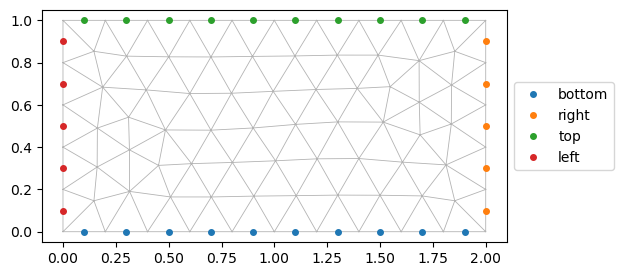

In [4]:
x, y = mesh.vertex_coordinates
fig, ax = plt.subplots(figsize=(6, 3.4))
ax.triplot(x, y, mesh.cell_vertices.T[:, :3], color="0.7", lw=0.6)
for k, name in enumerate(mesh.boundary_conditions_sorted_names):
    sel = mesh.boundary_face_function_numbers == k
    c = mesh.face_centers[mesh.boundary_face_face_indices[sel]]
    ax.plot(c[:, 0], c[:, 1], "o", ms=4, label=name)
ax.set_aspect("equal")
ax.legend(loc="center left", bbox_to_anchor=(1, 0.5))
plt.show()

In [5]:
assert np.isclose(mesh.cell_volumes[:n].sum(), 2.0)
assert counts.sum() == mesh.n_boundary_faces
assert list(tags) == list(mesh.boundary_conditions_sorted_physical_tags)